In [13]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
#import pandas as pd
#import os
import glob
#import shutil

import xarray as xr
#import numpy as np
#from pyhomogenize import open_xrdataset
#import seaborn as sns
#
#import matplotlib as mpl
#import matplotlib.pyplot as plt
#import cftime

In [28]:
from plotting_tools_africa import directory_available, plot_4diff,plot_absolut
from plotting_tools_exposure import plot_diff_pop, plot_absolute_pop, plot_diff_exposure
from format_data_tools import save_file_to_netcdf
from colors_indices import colorsteps_diff, colorsteps_absolute, colorsteps_exposure
from exposure import diff_exposure

In [29]:
# Directories need to be defined
pop_dir = '/work/ch0636/g300047/cicles/population/'
#database='/work/ch0636/g300047/cicles/'
data_dir='/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22/'
#data_dir = database + '/climate_fact_data/results_bulletin/'
plot_dir = '/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure/'

In [6]:
directory_available(plot_dir)

In [7]:
def sel_time_mean(ds, start, end):
    return ds.sel(time=slice(start, end)).mean(dim="time")

Only needs to be done once

### Next Box: 
#### Only execute once, or delete output file before

In [8]:
# get list of population diff and absolute files
pop_ssp1 = [
    pop_dir+ '/pop_1991_2020_ssp1.nc',
    pop_dir+ '/pop_2031_2060_ssp1.nc',
    pop_dir+ '/pop_2069_2098_ssp1.nc']
pop_ssp3 = [
    pop_dir+ '/pop_1991_2020_ssp3.nc',
    pop_dir+ '/pop_2031_2060_ssp3.nc',
    pop_dir+ '/pop_2069_2098_ssp3.nc']
pop_diff_ssp1 = [
    pop_dir+ '/pop_diff_2031_2060_ssp1.nc',
    pop_dir+ '/pop_diff_2069_2098_ssp1.nc']
pop_diff_ssp3 = [
    pop_dir+ '/pop_diff_2031_2060_ssp3.nc',
    pop_dir+ '/pop_diff_2069_2098_ssp3.nc']
pop_diff_ssp1


['/work/ch0636/g300047/cicles/population//pop_diff_2031_2060_ssp1.nc',
 '/work/ch0636/g300047/cicles/population//pop_diff_2069_2098_ssp1.nc']

## climate data in this case it is SU40

In [34]:
# Detemine the variable 
# Time resolution you like
#var='SU30'
#var='SU35'
#var='SU40'
var='TR'
#var='R20mm'
#var='DD'

robust='_ensemble-robustness.nc'
list_rcp26 = "rcp26"
list_rcp85 = "rcp85"
title_part="Ensemble Median of the change compared to 1991-2020: \n "

#### Check if title_part is consitent with file you are reading, you can chose between median and mean

In [35]:
# Get the list of files for difference plots
timefreq='year_2'
# Chose if you like median or mean 
what='_time-mean_ensemble-diff-median.nc'
sims_rcp26_diff = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp26+'*'+what)
sims_rcp85_diff = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp85+'*'+what)
robust_rcp26 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp26+'*'+robust)
robust_rcp85 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp85+'*'+robust)
# Sort the files to ensure correct order
sims_rcp26_diff.sort()
sims_rcp85_diff.sort()
robust_rcp26.sort()
robust_rcp85.sort()

In [37]:
# Have a look which files are being processed:
sims_rcp26_diff

['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2031_2060_rcp26_time-mean_ensemble-diff-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2069_2098_rcp26_time-mean_ensemble-diff-median.nc']

In [38]:
# Get the list of files for absolute plots
timefreq='year'
what='_time-mean_ensemble-median.nc'
sims_rcp26 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp26+'*'+what)
sims_rcp85 = glob.glob(data_dir+'/'+var+'/'+var+'*'+timefreq+'*'+list_rcp85+'*'+what)
# Sort the files to ensure correct order
sims_rcp26.sort()
sims_rcp85.sort()

In [40]:
# check
sims_rcp85

['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_1991_2020_rcp85_time-mean_ensemble-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2031_2060_rcp85_time-mean_ensemble-median.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2069_2098_rcp85_time-mean_ensemble-median.nc']

### For the plots you have to make some decisions in the next box:
* Do you like to plot West Africa (True) or Africa (False)
* user_dpi is the resolution of the saved figure, for printing 1200 is recommended, otherwise use 300, which is faster
* title: add a title to the plot according to your file selection (median, mean, etc)

Selected colors, levels for plotting  TR
['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_1991_2020_rcp26_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2031_2060_rcp26_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2069_2098_rcp26_time-mean_ensemble-median.nc']
['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_1991_2020_rcp85_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2031_2060_rcp85_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2069_2098_rcp85_time-mean_ensemble-median.nc']
sims_rcp26 ['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_1991_2020_rcp26_time-mean_ensemble-median.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:539: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0.03, 0.08, 0.97, 0.93])


file is here: /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//TR_absolut_West_Africa_1200.png
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//TR_absolut_West_Africa_1200.png


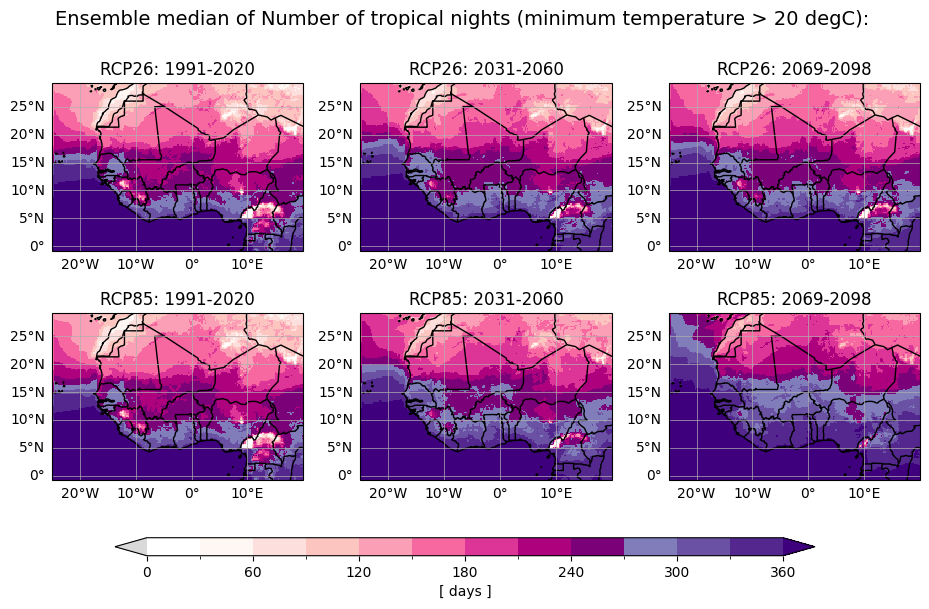

In [41]:
print('Selected colors, levels for plotting ', var)
color_steps, level_steps = colorsteps_absolute(var)

# Now plot the absolute values
plot_absolut(
    sims_rcp26,
    sims_rcp85,
    level_steps, 
    color_steps,    
    plot_dir,
    title="Ensemble median of",
    var=var,
    westafrica=True,
    user_dpi=1200,
    rows=2, 
    columns=3,
    )

In [15]:
pop_ssp1

['/work/ch0636/g300047/cicles/population//pop_1991_2020_ssp1.nc',
 '/work/ch0636/g300047/cicles/population//pop_2031_2060_ssp1.nc',
 '/work/ch0636/g300047/cicles/population//pop_2069_2098_ssp1.nc']

['/work/ch0636/g300047/cicles/population//pop_1991_2020_ssp1.nc', '/work/ch0636/g300047/cicles/population//pop_2031_2060_ssp1.nc', '/work/ch0636/g300047/cicles/population//pop_2069_2098_ssp1.nc']
['/work/ch0636/g300047/cicles/population//pop_1991_2020_ssp3.nc', '/work/ch0636/g300047/cicles/population//pop_2031_2060_ssp3.nc', '/work/ch0636/g300047/cicles/population//pop_2069_2098_ssp3.nc']
/work/ch0636/g300047/cicles/population//pop_1991_2020_ssp1.nc
/work/ch0636/g300047/cicles/population//pop_2031_2060_ssp1.nc
/work/ch0636/g300047/cicles/population//pop_2069_2098_ssp1.nc
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//number_of_people_absolut_West_Africa_1200.png


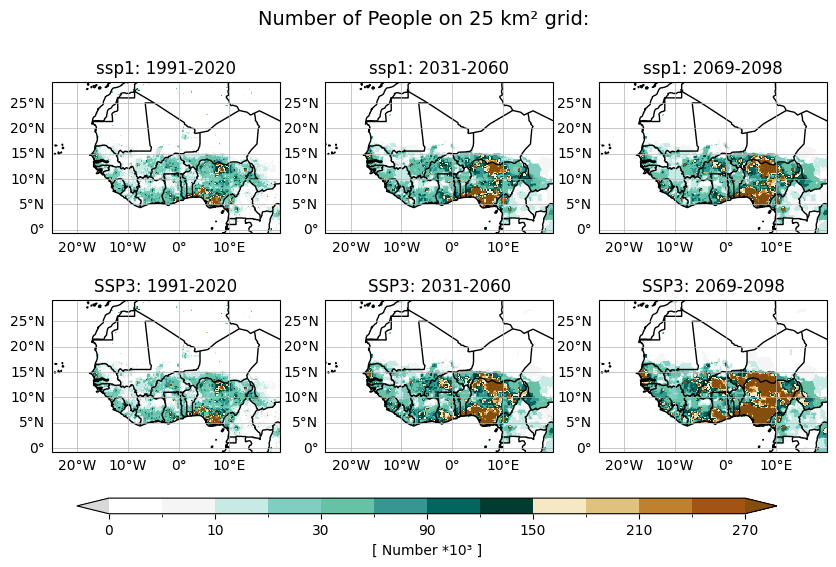

In [16]:
color_steps, level_steps = colorsteps_absolute('number_of_people')
plot_absolute_pop(
    pop_ssp1,
    pop_ssp3,
    level_steps, 
    color_steps,    
    plot_dir,
    title="on 25 km² grid",
    var='number_of_people',
    westafrica=True,
    user_dpi=1200,
    rows=2, 
    columns=3,
    )

In [30]:
# look at input files

df = xr.open_dataset(sims_rcp26_diff[0], decode_timedelta=False)
df= xr.open_dataset(pop_diff_ssp3[0], decode_timedelta=False)
df['number_of_people'].to_dataframe().describe()
#df['SU40'].to_dataframe().describe()

,lon,lat,number_of_people
count,155976.000000,155976.000000,1.559760e+05
mean,17.820000,-1.760000,9.411241e+03
std,24.641307,25.530432,5.037492e+04
min,-24.750000,-45.870000,-1.282363e+06
25%,-3.465000,-23.870000,0.000000e+00
50%,17.820000,-1.760000,0.000000e+00
75%,39.105000,20.350000,2.693453e+03
max,60.390000,42.350000,2.896327e+06


file:  /work/ch0636/g300047/cicles/population//pop_diff_2031_2060_ssp1.nc
file:  /work/ch0636/g300047/cicles/population//pop_diff_2069_2098_ssp1.nc
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//number_of_people_diff_West_Africa_1200.png


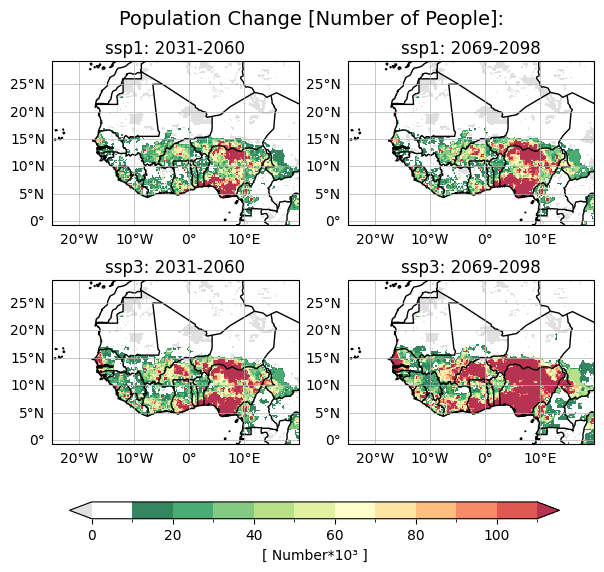

In [17]:
color_steps_diff, level_steps_diff = colorsteps_diff('number_of_people')

#Plot 2 diff for population
plot_diff_pop(
     pop_diff_ssp1,
     pop_diff_ssp3,
     level_steps_diff, 
     color_steps_diff, 
     plot_dir,
     title='Population Change',
     var='number_of_people',
     #westafrica=False, 
     westafrica=True,
     user_dpi=1200,
     rows=2, 
     columns=2,
     row_gap=0.35,
     wspace=None
    )


In [18]:
robust_rcp26

['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2031_2060_rcp26_ensemble-robustness.nc',
 '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//SU40/SU40_year_2069_2098_rcp26_ensemble-robustness.nc']

Selected colors, levels for plotting  TR
/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2031_2060_rcp26_time-mean_ensemble-diff-median.nc
nothing to do, unit exists


/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:336: FutureWarning: In a future version, xarray will not decode the variable 'TR' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  datar = xr.open_dataset(robust_rcp26)


/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2069_2098_rcp26_time-mean_ensemble-diff-median.nc
nothing to do, unit exists


/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:336: FutureWarning: In a future version, xarray will not decode the variable 'TR' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  datar = xr.open_dataset(robust_rcp26)
/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:369: FutureWarning: In a future version, xarray will not decode the variable 'TR' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the prese

plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//TR_diff-robust_West_Africa_300.png


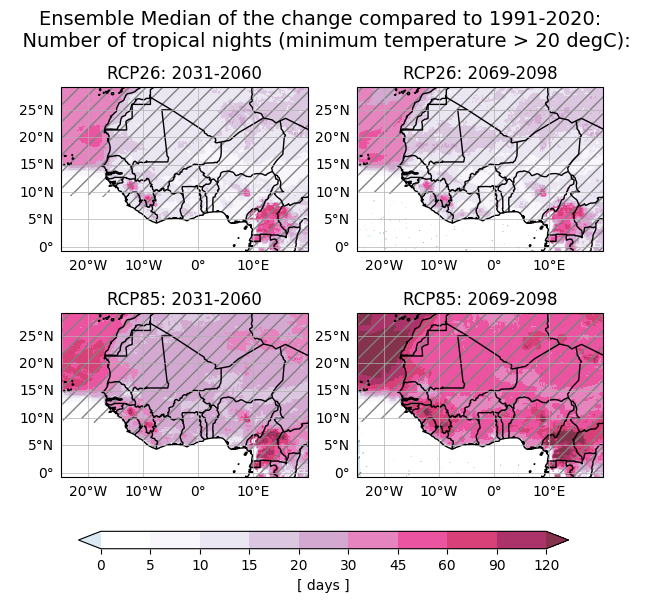

In [42]:
# get colors and levels for plotting
print('Selected colors, levels for plotting ', var)

color_steps_diff, level_steps_diff = colorsteps_diff(var)

plot_4diff(
     sims_rcp26_diff,
     sims_rcp85_diff,
     robust_rcp26,
     robust_rcp85,
     level_steps_diff,
     color_steps_diff,
     what,
     robust,
     plot_dir,
     title=title_part,
     var=var,
     robustness=True,
     #westafrica=False, 
     westafrica=True,
     user_dpi=300,
     rows=2, 
     columns=2,
     row_gap=-0.05,
     wspace=None
    )

In [20]:
pop_diff_ssp1

['/work/ch0636/g300047/cicles/population//pop_diff_2031_2060_ssp1.nc',
 '/work/ch0636/g300047/cicles/population//pop_diff_2069_2098_ssp1.nc']

In [21]:
def get_time_slice(n: int) -> str:
    """
    Return the time slice string for index n.
    n=0 -> '2031_2060'
    n=1 -> '2069_2098'
    """
    if n == 0:
        return '2031_2060'
    if n == 1:
        return '2069_2098'
    raise ValueError(f"Unsupported index {n}; expected 0 or 1.")

# Example:
# time_slice = get_time_slice(n)

In [43]:
# Here for Factsheet:
exposure_change_ssp1 = []
exposure_change_ssp3 = []
exposure_ssp1 = []
exposure_ssp3 = []
for n in range(0, 2):
    change_ssp1 = diff_exposure(pop_ssp1[0], sims_rcp26[0], pop_diff_ssp1[n], sims_rcp26_diff[n], var)
    change_ssp3 = diff_exposure(pop_ssp3[0], sims_rcp85[0], pop_diff_ssp3[n], sims_rcp85_diff[n], var)
    
    time_slice = get_time_slice(n)
    save_file_to_netcdf(change_ssp1, pop_dir, f'/{var}_year_{time_slice}_ssp1_exposure_change.nc')
    save_file_to_netcdf(change_ssp3, pop_dir, f'/{var}_year_{time_slice}_ssp3_exposure_change.nc')
    
    exposure_change_ssp1.append(change_ssp1)
    exposure_change_ssp3.append(change_ssp3)
    exposure_ssp1.append(pop_dir+ f'/{var}_year_{time_slice}_ssp1_exposure_change.nc')
    exposure_ssp3.append(pop_dir+ f'/{var}_year_{time_slice}_ssp3_exposure_change.nc')

In [44]:
exposure_ssp3

['/work/ch0636/g300047/cicles/population//TR_year_2031_2060_ssp3_exposure_change.nc',
 '/work/ch0636/g300047/cicles/population//TR_year_2069_2098_ssp3_exposure_change.nc']

Exposure of population to :  TR


<xarray.Dataset> Size: 4MB
Dimensions:   (rlat: 402, rlon: 388)
Coordinates:
  * rlat      (rlat) float64 3kB -45.87 -45.65 -45.43 ... 41.91 42.13 42.35
  * rlon      (rlon) float64 3kB -24.75 -24.53 -24.31 ... 59.95 60.17 60.39
    lon       (rlat, rlon) float64 1MB ...
    lat       (rlat, rlon) float64 1MB ...
    height    float64 8B ...
Data variables:
    exposure  (rlat, rlon) float64 1MB ...

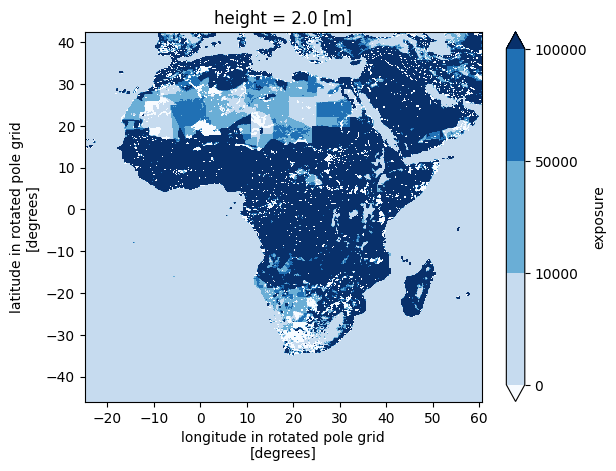

In [45]:
print('Exposure of population to : ',var)
ssp1 = xr.open_dataset(exposure_ssp1[0],decode_timedelta=False)
#exposure_ssp3 = xr.open_dataset(exposure_ssp3[0],decode_timedelta=False)
ssp1['exposure'].plot(levels=[0,10000,50000,100000], cmap='Blues', add_colorbar=True)
ssp1

In [46]:
print('Exposure of population to : ',var)
print('for the following files:')
print(exposure_ssp1)
print(exposure_ssp3)
print(robust_rcp26)
print(robust_rcp85)

Exposure of population to :  TR
for the following files:
['/work/ch0636/g300047/cicles/population//TR_year_2031_2060_ssp1_exposure_change.nc', '/work/ch0636/g300047/cicles/population//TR_year_2069_2098_ssp1_exposure_change.nc']
['/work/ch0636/g300047/cicles/population//TR_year_2031_2060_ssp3_exposure_change.nc', '/work/ch0636/g300047/cicles/population//TR_year_2069_2098_ssp3_exposure_change.nc']
['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2031_2060_rcp26_ensemble-robustness.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2069_2098_rcp26_ensemble-robustness.nc']
['/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2031_2060_rcp85_ensemble-robustness.nc', '/work/ch0636/g300047/cicles/climate_fact_data/hori_results_afr22//TR/TR_year_2069_2098_rcp85_ensemble-robustness.nc']


In [25]:
df= xr.open_dataset(robust_rcp26[0], decode_timedelta=False)
df['SU40'].long_name

'Ensemble robustness'

Selected colors, levels for plotting  TR


/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_exposure.py:27: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  title="",
/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_exposure.py:27: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  title="",
/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_exposure.py:27: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  title="",
/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_exposure.py:27: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_

/work/ch0636/g300047/cicles/population//TR_year_2031_2060_ssp1_exposure_change.nc
/work/ch0636/g300047/cicles/population//TR_year_2069_2098_ssp1_exposure_change.nc
plot ist saved in :  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/horizontal-plots-exposure//exposure_TR_diff-robust_West_Africa_300.png


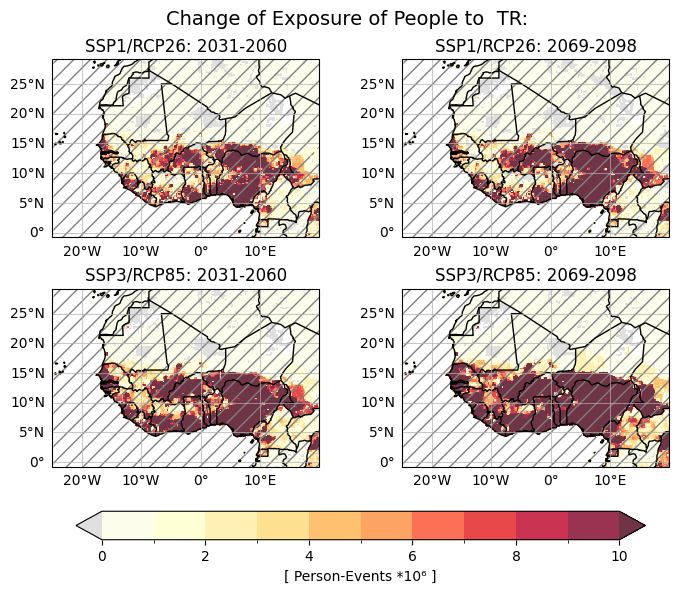

In [48]:
print('Selected colors, levels for plotting ', var)

color_steps_exp, level_steps_exp = colorsteps_exposure('exposure')

plot_diff_exposure(
     exposure_ssp1,
     exposure_ssp3,
     robust_rcp26,
     robust_rcp85,
     plot_dir,
     level_steps_exp, 
     color_steps_exp,
     title='Change of Exposure of People to ', # unit person-events
     var='exposure',
     varr='TR',
     robustness=True,
     #westafrica=False, 
     westafrica=True,
     user_dpi=300,
     rows=2, 
     columns=2,
    )